In [1]:
!pip install pandas numpy matplotlib scikit-learn xgboost interpret shap seaborn openpyxl

Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import GroupShuffleSplit

print("Libraries imported successfully.")

Libraries imported successfully.


Loading the dataset

In [4]:
df = pd.read_csv("dataset.csv")
raw_df = df.copy()

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


 Inspecting the dataset

In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 101766
Columns: 50

Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,101766,6,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,101766,10,?,98569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


Target Variable

In [8]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [9]:
df["readmitted"].value_counts(normalize=True) * 100 #percentage value

readmitted
NO     53.911916
>30    34.928169
<30    11.159916
Name: proportion, dtype: float64

In [10]:
df["target"] = (df["readmitted"] == "<30").astype(int) #creating the target

In [11]:
df["target"].value_counts()

target
0    90409
1    11357
Name: count, dtype: int64

In [12]:
df["target"].value_counts(normalize=True) * 100

target
0    88.840084
1    11.159916
Name: proportion, dtype: float64

Checking patients and repeated encounters

In [13]:
print("Total encounters:", len(df))
print("Unique patients:", df["patient_nbr"].nunique())

Total encounters: 101766
Unique patients: 71518


In [14]:
encounters_per_patient = df.groupby("patient_nbr").size()

print(encounters_per_patient.describe())

count    71518.000000
mean         1.422942
std          1.090740
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
dtype: float64


In [15]:
print(
    "Patients with more than one encounter:",
    (encounters_per_patient > 1).sum()
)

Patients with more than one encounter: 16773


Handling missing values

In [16]:
missing_values = (df == "?").sum()

In [17]:
missing_values[missing_values > 0].sort_values(
    ascending=False
)

weight               98569
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

In [18]:
df = df.drop(columns=["weight"])

In [19]:
df = df.replace("?", np.nan)

In [20]:
df.head()

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,target
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,NaN,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


In [21]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

In [22]:
df["discharge_disposition_id"].value_counts().sort_index()

discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

In [23]:
#finding deaths and hospice encounters
death_codes = [11, 19, 20, 21]

hospice_codes = [13, 14]

death_encounters = df[
    df["discharge_disposition_id"].isin(death_codes)
]

hospice_encounters = df[
    df["discharge_disposition_id"].isin(hospice_codes)
]
print("Death encounters:", len(death_encounters))
print("Hospice encounters:", len(hospice_encounters))

Death encounters: 1652
Hospice encounters: 771


In [24]:
death_hospice_mask = df["discharge_disposition_id"].isin(
    [11, 13, 14, 19, 20, 21]
)

print("Death/hospice encounters:", death_hospice_mask.sum())

Death/hospice encounters: 2423


In [25]:
df.loc[
    death_hospice_mask,
    "discharge_disposition_id"
].value_counts().sort_index()

discharge_disposition_id
11    1642
13     399
14     372
19       8
20       2
Name: count, dtype: int64

In [26]:
percentage = (
    death_hospice_mask.sum() / len(df)
) * 100

print(f"Percentage of encounters removed: {percentage:.2f}%")

Percentage of encounters removed: 2.38%


In [27]:
# excluding death/hospice discharge encounters and remove duplicate encounters
death_hospice_codes = [11, 13, 14, 19, 20, 21]
death_hospice_mask = df["discharge_disposition_id"].isin(death_hospice_codes)
print("Death/hospice encounters excluded:", int(death_hospice_mask.sum()))
df = df.loc[~death_hospice_mask].copy()

duplicate_encounters = int(df["encounter_id"].duplicated().sum())
print("Duplicate encounter IDs excluded:", duplicate_encounters)
df = df.drop_duplicates(subset=["encounter_id"], keep="first").copy()


Death/hospice encounters excluded: 2423
Duplicate encounter IDs excluded: 0


In [28]:
df.reset_index(drop=True, inplace=True)

In [29]:
df["discharge_disposition_id"].value_counts().sort_index()

discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
12        3
15       63
16       11
17       14
18     3691
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

In [30]:
print(
    df["discharge_disposition_id"]
    .isin([11, 13, 14, 19, 20, 21])
    .sum()
)

0


Defining the adult cohort

In [31]:
print(df["age"].value_counts().sort_index())

age
[0-10)        160
[10-20)       690
[20-30)      1649
[30-40)      3764
[40-50)      9607
[50-60)     17060
[60-70)     22059
[70-80)     25331
[80-90)     16434
[90-100)     2589
Name: count, dtype: int64


In [32]:
df = df[~df["age"].isin(["[0-10)", "[10-20)"])].copy().reset_index(drop=True)

In [33]:
print("Remaining records:", len(df))

Remaining records: 98493


In [34]:
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True) * 100)

target
0    87222
1    11271
Name: count, dtype: int64
target
0    88.556547
1    11.443453
Name: proportion, dtype: float64


In [35]:
print(df["race"].value_counts(dropna=False))
print(df["gender"].value_counts(dropna=False))
print(df["age"].value_counts(dropna=False).sort_index())

race
Caucasian          73647
AfricanAmerican    18547
NaN                 2225
Hispanic            1992
Other               1458
Asian                624
Name: count, dtype: int64
gender
Female             52970
Male               45520
Unknown/Invalid        3
Name: count, dtype: int64
age
[20-30)      1649
[30-40)      3764
[40-50)      9607
[50-60)     17060
[60-70)     22059
[70-80)     25331
[80-90)     16434
[90-100)     2589
Name: count, dtype: int64


Target visualisation

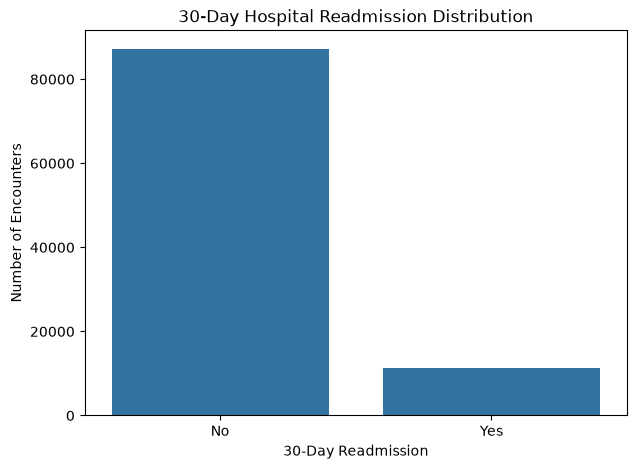

In [36]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("30-Day Hospital Readmission Distribution")
plt.xlabel("30-Day Readmission")
plt.ylabel("Number of Encounters")
plt.xticks([0, 1], ["No", "Yes"]) #changing label name

plt.show()

In [37]:
def calculate_readmission_rate(data, group_column):
    
    result = (
        data.groupby(group_column)["target"]
        .agg(
            Patients="count",
            Readmitted="sum"
        )
        .reset_index()
    )
    
    result["Readmission Rate (%)"] = (
        result["Readmitted"] / result["Patients"] * 100
    )
    
    return result

In [38]:
#readmission rate for the race
race_rate = calculate_readmission_rate(df, "race")

race_rate

,race,Patients,Readmitted,Readmission Rate (%)
0,AfricanAmerican,18547,2136,11.516687
1,Asian,624,65,10.416667
2,Caucasian,73647,8527,11.578204
3,Hispanic,1992,212,10.642570
4,Other,1458,143,9.807956


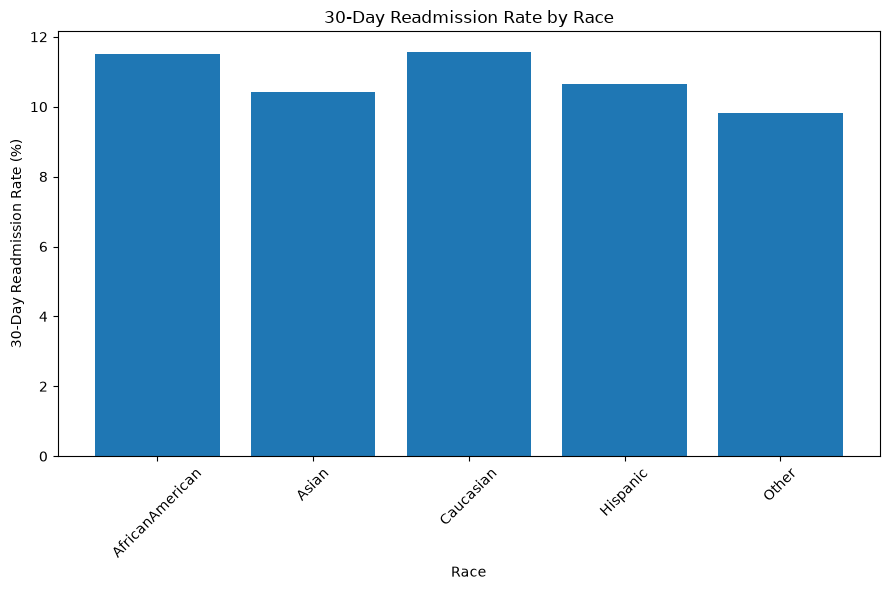

In [39]:
plt.figure(figsize=(9, 6))

plt.bar(
    race_rate["race"],
    race_rate["Readmission Rate (%)"]
)

plt.xlabel("Race")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate by Race")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
#readmission rate for the age group
age_rate = calculate_readmission_rate(df, "age")

age_rate

,age,Patients,Readmitted,Readmission Rate (%)
0,[20-30),1649,236,14.311704
1,[30-40),3764,424,11.264612
2,[40-50),9607,1024,10.658895
3,[50-60),17060,1667,9.771395
4,[60-70),22059,2493,11.301510
5,[70-80),25331,3054,12.056374
6,[80-90),16434,2065,12.565413
7,[90-100),2589,308,11.896485


In [41]:
age_order = [
    "[20-30)",
    "[30-40)",
    "[40-50)",
    "[50-60)",
    "[60-70)",
    "[70-80)",
    "[80-90)",
    "[90-100)"
]

age_rate["age"] = pd.Categorical(
    age_rate["age"],
    categories=age_order,
    ordered=True
)

age_rate = age_rate.sort_values("age")

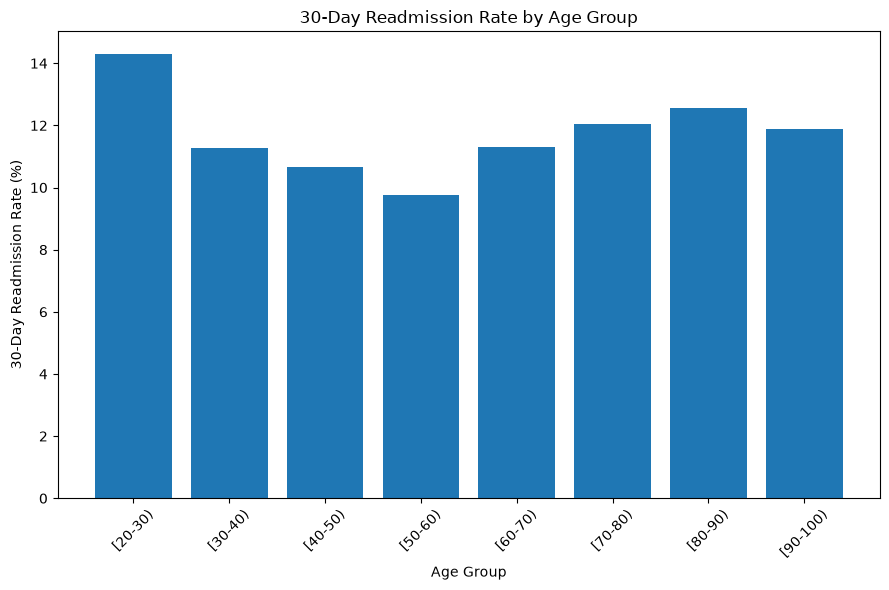

In [42]:
plt.figure(figsize=(9, 6))

plt.bar(
    age_rate["age"].astype(str),
    age_rate["Readmission Rate (%)"]
)

plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate by Age Group")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
#readmission rate for the gender
gender_rate = calculate_readmission_rate(df, "gender")

gender_rate

,gender,Patients,Readmitted,Readmission Rate (%)
0,Female,52970,6103,11.521616
1,Male,45520,5168,11.353251
2,Unknown/Invalid,3,0,0.000000


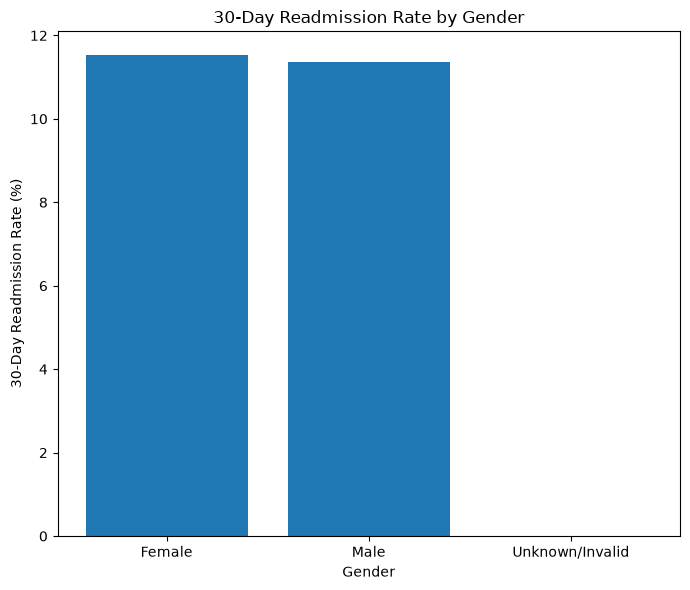

In [44]:
plt.figure(figsize=(7, 6))

plt.bar(
    gender_rate["gender"],
    gender_rate["Readmission Rate (%)"]
)

plt.xlabel("Gender")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate by Gender")

plt.tight_layout()
plt.show()

In [45]:
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Dataset shape: (98493, 50)

Target distribution:
target
0    87222
1    11271
Name: count, dtype: int64

Missing values:
max_glu_serum               93356
A1Cresult                   82102
medical_specialty           48362
payer_code                  38789
race                         2225
diag_3                       1102
diag_2                        220
diag_1                         20
patient_nbr                     0
encounter_id                    0
time_in_hospital                0
admission_source_id             0
num_procedures                  0
num_lab_procedures              0
admission_type_id               0
discharge_disposition_id        0
age                             0
gender                          0
number_inpatient                0
number_emergency                0
dtype: int64


In [46]:
#prepare data for model training
y = df["target"].astype(int).reset_index(drop=True)
groups = df["patient_nbr"].reset_index(drop=True).copy()

identifier_and_outcome_columns = [
    "target", "readmitted", "encounter_id", "patient_nbr"
]
X = df.drop(
    columns=[c for c in identifier_and_outcome_columns if c in df.columns]
).reset_index(drop=True).copy()

assert len(X) == len(y) == len(groups)
assert X.index.equals(y.index) and X.index.equals(groups.index)
assert not X.columns.isin(["target", "readmitted", "encounter_id", "patient_nbr"]).any()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)


X shape: (98493, 46)
y shape: (98493,)
groups shape: (98493,)


In [47]:
assert len(X) == len(y) == len(groups)
assert X.index.equals(y.index) and X.index.equals(groups.index)


In [48]:
print("X:", len(X))
print("y:", len(y))
print("groups:", len(groups))
assert len(X) == len(y) == len(groups)


X: 98493
y: 98493
groups: 98493


In [49]:
#patient level splitting to remove the same patient appearing in both training and testing sets
from sklearn.model_selection import GroupShuffleSplit

# Split into 70% training and 30% temporary

gss_train = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    gss_train.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
y_train = y.iloc[train_idx].copy()
groups_train = groups.iloc[train_idx].copy()

X_temp = X.iloc[temp_idx].copy()
y_temp = y.iloc[temp_idx].copy()
groups_temp = groups.iloc[temp_idx].copy()


# Split the 30% temporary set into 15% validation
#         and 15% testing

gss_val_test = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss_val_test.split(
        X_temp,
        y_temp,
        groups=groups_temp
    )
)

X_val = X_temp.iloc[val_idx].copy()
y_val = y_temp.iloc[val_idx].copy()
groups_val = groups_temp.iloc[val_idx].copy()

X_test = X_temp.iloc[test_idx].copy()
y_test = y_temp.iloc[test_idx].copy()
groups_test = groups_temp.iloc[test_idx].copy()

In [50]:
print("Train encounters:", len(X_train))
print("Validation encounters:", len(X_val))
print("Test encounters:", len(X_test))
print("Train patients:", groups_train.nunique())
print("Validation patients:", groups_val.nunique())
print("Test patients:", groups_test.nunique())

assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))
print("Patient overlap across splits: 0")


Train encounters: 68944
Validation encounters: 14820
Test encounters: 14729
Train patients: 48519
Validation patients: 10397
Test patients: 10398
Patient overlap across splits: 0


In [51]:
print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

Training records: (68944, 46)
Testing records: (14729, 46)


In [52]:
overlap = set(groups_train).intersection(set(groups_test))

print("Patients appearing in both train and test:", len(overlap)) #checking for any overlapping patients

Patients appearing in both train and test: 0


In [53]:
df.head(2)

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,target
0,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,No,No,No,Yes,NO,0
1,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,Up,No,No,No,No,No,Ch,Yes,NO,0


Finding categroical and numerical variables

In [54]:
df.dtypes

encounter_id                int64
patient_nbr                 int64
race                          str
gender                        str
age                           str
admission_type_id           int64
discharge_disposition_id    int64
admission_source_id         int64
time_in_hospital            int64
payer_code                    str
medical_specialty             str
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
number_outpatient           int64
number_emergency            int64
number_inpatient            int64
diag_1                        str
diag_2                        str
diag_3                        str
number_diagnoses            int64
max_glu_serum                 str
A1Cresult                     str
metformin                     str
repaglinide                   str
nateglinide                   str
chlorpropamide                str
glimepiride                   str
acetohexamide                 str
glipizide     

In [55]:
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("\nCategorical variables:")
print(categorical_features)

print("\nNumerical variables:")
print(numerical_features)


Categorical variables:
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Numerical variables:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [56]:
assert "target" not in X_train.columns
assert "readmitted" not in X_train.columns


In [57]:
print("readmitted" in X_train.columns)

False


In [58]:
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()
numerical_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

coded_categorical_features = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
]
for column in coded_categorical_features:
    if column in numerical_features:
        numerical_features.remove(column)
    if column in X_train.columns and column not in categorical_features:
        categorical_features.append(column)

print("Categorical variables:", categorical_features)
print("Numerical variables:", numerical_features)
print("Identifier/outcome leakage check:", {
    c: c in X_train.columns
    for c in ["target", "readmitted", "encounter_id", "patient_nbr"]
})


Categorical variables: ['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id']
Numerical variables: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Identifier/outcome leakage check: {'target': False, 'readmitted': False, 'encounter_id': False, 'patient_nbr': False}


In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numeric pipeline (filling missing values with median)
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline (filling missing values with most common category)
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")) #covert into numeric
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Training the Penalised Logistic Regression

In [60]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000, #iteration count
        random_state=42
    ))
])

In [61]:
logistic_model.fit(X_train, y_train)

print("Logistic regression training completed.")

Logistic regression training completed.


In [62]:
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1] #model's estimated probability of readmission for each test example

In [63]:
y_pred_lr = (y_prob_lr >= 0.5).astype(int)

In [64]:
from sklearn.metrics import roc_auc_score
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression ROC-AUC:", roc_auc_lr)

Logistic Regression ROC-AUC: 0.6676295958044833


In [65]:
from sklearn.metrics import average_precision_score
pr_auc_lr = average_precision_score(y_test, y_prob_lr)

print("Logistic Regression PR-AUC:", pr_auc_lr)

Logistic Regression PR-AUC: 0.22770624141717818


In [66]:
y_test.mean() #test-set readmission prevalence

np.float64(0.11188811188811189)

In [67]:
from sklearn.metrics import confusion_matrix
def calculate_metrics(y_true, y_prob, threshold=0.5):
    
    y_pred = (y_prob >= threshold).astype(int)
    
    tn, fp, fn,  tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0 #of all patients who actually were readmitted (TPR)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0 #of all patients who were not readmitted
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0 #how often the predicted readmission are actually correct
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0 #how often the predicted no readmission are actually correct
    
    return {
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "PPV": ppv,
        "NPV": npv
    }

In [68]:
lr_metrics = calculate_metrics(
    y_test,
    y_prob_lr,
    threshold=0.5
)

lr_metrics

{'Sensitivity': np.float64(0.028519417475728157),
 'Specificity': np.float64(0.9968656830517545),
 'PPV': np.float64(0.5340909090909091),
 'NPV': np.float64(0.8906495457960522)}

In [69]:
#barier Score
from sklearn.metrics import brier_score_loss
brier_lr = brier_score_loss(
    y_test,
    y_prob_lr
)

print("Logistic Regression Brier Score:", brier_lr)

Logistic Regression Brier Score: 0.09468380644237263


Calibration Curve

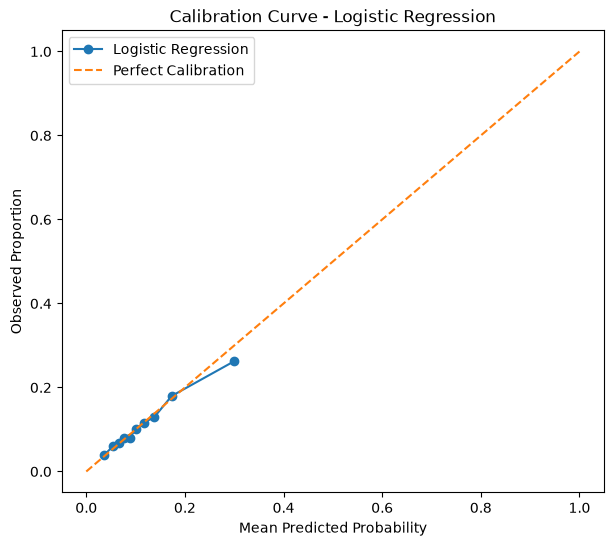

In [70]:
from sklearn.calibration import calibration_curve

prob_true_lr, prob_pred_lr = calibration_curve(
    y_test,
    y_prob_lr,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred_lr,
    prob_true_lr,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Proportion")
plt.title("Calibration Curve - Logistic Regression")

plt.legend()
plt.show()

Cross-validation for Logistic Regression

In [71]:
#group validation for multiple encounters for the same patient
from sklearn.model_selection import StratifiedGroupKFold 

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [72]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Use the existing patient-level CV splits
cv_splits = list(
    cv.split(X_train, y_train, groups_train)
)

grid_lr = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid_lr,
    scoring="roc_auc",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

grid_lr.fit(X_train, y_train)

print("Best parameters:", grid_lr.best_params_)
print("Best CV ROC-AUC:", grid_lr.best_score_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best parameters: {'model__C': 0.01}
Best CV ROC-AUC: 0.6625459610845836


In [73]:
best_lr = grid_lr.best_estimator_ #retrieving best performinf LR pipeline

In [74]:
y_prob_lr = best_lr.predict_proba(X_test)[:, 1]

In [75]:
#tuned model on the held out test set
print(
    "Test ROC-AUC:",
    roc_auc_score(y_test, y_prob_lr)
)

print(
    "Test PR-AUC:",
    average_precision_score(y_test, y_prob_lr)
)

print(
    "Brier Score:",
    brier_score_loss(y_test, y_prob_lr)
)

Test ROC-AUC: 0.678070561839116
Test PR-AUC: 0.2307799944673562
Brier Score: 0.09449442800278501


EBM (Explainable Boosting Machine) model Training

In [76]:
X_train_ebm = X_train.copy()
X_test_ebm = X_test.copy()

In [77]:
#converting categorical variables into string
for col in categorical_features:
    X_train_ebm[col] = X_train_ebm[col].fillna("Unknown").astype(str)
    X_test_ebm[col] = X_test_ebm[col].fillna("Unknown").astype(str)

In [78]:
#handling missing values for numerical variables
for col in numerical_features:
    median_value = X_train_ebm[col].median()
    
    X_train_ebm[col] = X_train_ebm[col].fillna(median_value)
    X_test_ebm[col] = X_test_ebm[col].fillna(median_value)

In [79]:
#training the model
from interpret.glassbox import ExplainableBoostingClassifier

ebm = ExplainableBoostingClassifier(
    interactions=10, #capturing relationship between features
    max_bins=256, #controlling the representation of numerical values
    learning_rate=0.05, #model learning control
    max_rounds=1000, #model iteration
    random_state=42
)

ebm.fit(X_train_ebm, y_train)

print("EBM training completed.")

EBM training completed.


In [80]:
y_prob_ebm = ebm.predict_proba(X_test_ebm)[:, 1]

y_pred_ebm = (
    y_prob_ebm >= 0.5
).astype(int)

In [81]:
roc_auc_ebm = roc_auc_score(
    y_test,
    y_prob_ebm
)

pr_auc_ebm = average_precision_score(
    y_test,
    y_prob_ebm
)

brier_ebm = brier_score_loss(
    y_test,
    y_prob_ebm
)

print("EBM ROC-AUC:", roc_auc_ebm)
print("EBM PR-AUC:", pr_auc_ebm)
print("EBM Brier Score:", brier_ebm)

EBM ROC-AUC: 0.6816818360283906
EBM PR-AUC: 0.2332708277244806
EBM Brier Score: 0.09413019280961174


In [82]:
ebm_global = ebm.explain_global()

ebm_global

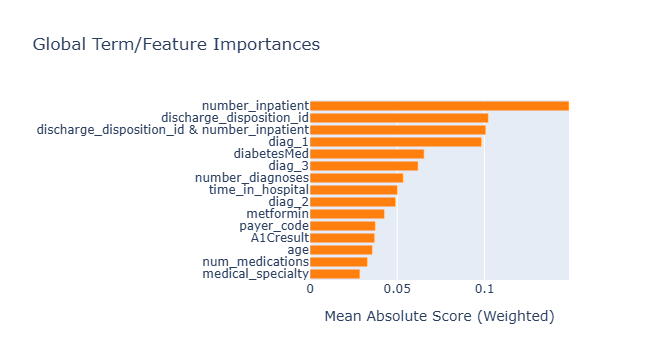

In [83]:
ebm_global.visualize()

XGBoost Training

In [84]:
xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore"
                ))
            ]),
            categorical_features
        )
    ]
)

In [85]:
#class imbalance calculating in the training data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 7.690785327114584


In [86]:
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ("preprocessor", xgb_preprocessor),
        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [87]:
xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [88]:
#XGBoost probabilities
y_prob_xgb = xgb_model.predict_proba(
    X_test
)[:, 1]

In [89]:
roc_auc_xgb = roc_auc_score(
    y_test,
    y_prob_xgb
)

pr_auc_xgb = average_precision_score(
    y_test,
    y_prob_xgb
)

brier_xgb = brier_score_loss(
    y_test,
    y_prob_xgb
)

print("XGBoost ROC-AUC:", roc_auc_xgb)
print("XGBoost PR-AUC:", pr_auc_xgb)
print("XGBoost Brier Score:", brier_xgb)

XGBoost ROC-AUC: 0.6847736619405749
XGBoost PR-AUC: 0.2426218024024914
XGBoost Brier Score: 0.21437039971351624


In [90]:
xgb_metrics = calculate_metrics(
    y_test,
    y_prob_xgb,
    threshold=0.5
)

xgb_metrics

{'Sensitivity': np.float64(0.6031553398058253),
 'Specificity': np.float64(0.6720434217567465),
 'PPV': np.float64(0.18811506434519304),
 'NPV': np.float64(0.9307570142932768)}

In [91]:
%pip install fairlearn

Note: you may need to restart the kernel to use updated packages.


In [92]:
from sklearn.model_selection import GroupShuffleSplit #RQ3

validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=43
)

cal_idx, threshold_idx = next(
    validation_splitter.split(
        X_val,
        y_val,
        groups=groups_val
    )
)

#for calibrating the model's predicted probabilities
X_cal = X_val.iloc[cal_idx].copy()
y_cal = y_val.iloc[cal_idx].copy()
groups_cal = groups_val.iloc[cal_idx].copy()

#for choosing a decision cutoff
X_threshold = X_val.iloc[threshold_idx].copy()
y_threshold = y_val.iloc[threshold_idx].copy()
groups_threshold = groups_val.iloc[threshold_idx].copy()

#checks that no patients appear in both parts
assert set(groups_cal).isdisjoint(set(groups_threshold))

print("Calibration encounters:", len(X_cal))
print("Threshold-selection encounters:", len(X_threshold))

Calibration encounters: 7437
Threshold-selection encounters: 7383


In [93]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibrated_xgb = CalibratedClassifierCV(
    estimator=FrozenEstimator(xgb_model),
    method="sigmoid"
)

calibrated_xgb.fit(X_cal, y_cal)

y_prob_threshold_cal = calibrated_xgb.predict_proba(
    X_threshold
)[:, 1]

y_prob_xgb_cal = calibrated_xgb.predict_proba(
    X_test
)[:, 1]

calibration_comparison = pd.DataFrame([
    {
        "Model": "XGBoost raw",
        "ROC-AUC": roc_auc_score(y_test, y_prob_xgb),
        "AP": average_precision_score(y_test, y_prob_xgb),
        "Brier": brier_score_loss(y_test, y_prob_xgb)
    },
    {
        "Model": "XGBoost calibrated",
        "ROC-AUC": roc_auc_score(y_test, y_prob_xgb_cal),
        "AP": average_precision_score(y_test, y_prob_xgb_cal),
        "Brier": brier_score_loss(y_test, y_prob_xgb_cal)
    }
])

calibration_comparison

,Model,ROC-AUC,AP,Brier
0,XGBoost raw,0.684774,0.242622,0.21437
1,XGBoost calibrated,0.684774,0.242622,0.09383


In [94]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_threshold,
    y_prob_threshold_cal
)

valid = np.isfinite(thresholds)

# Maximising TPR - FPR also maximises balanced accuracy.
best_position = np.argmax(
    tpr[valid] - fpr[valid]
)

global_threshold = float(
    thresholds[valid][best_position]
)

y_pred_before = (
    y_prob_xgb_cal >= global_threshold
).astype(int)

print("Selected global threshold:", global_threshold)

Selected global threshold: 0.10666526983717327


In [95]:
#comparing models
results = pd.DataFrame({
    "Model": [
        "Penalised Logistic Regression",
        "Explainable Boosting Machine",
        "Calibrated XGBoost"
    ],
    
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_ebm),
        roc_auc_score(y_test, y_prob_xgb_cal)
    ],
    
    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_ebm),
        average_precision_score(y_test, y_prob_xgb_cal)
    ],
    
    "Brier Score": [
        brier_score_loss(y_test, y_prob_lr),
        brier_score_loss(y_test, y_prob_ebm),
        brier_score_loss(y_test, y_prob_xgb_cal)
    ]
})

results

,Model,ROC-AUC,PR-AUC,Brier Score
0,Penalised Logistic Regression,0.678071,0.230780,0.094494
1,Explainable Boosting Machine,0.681682,0.233271,0.094130
2,Calibrated XGBoost,0.684774,0.242622,0.093830


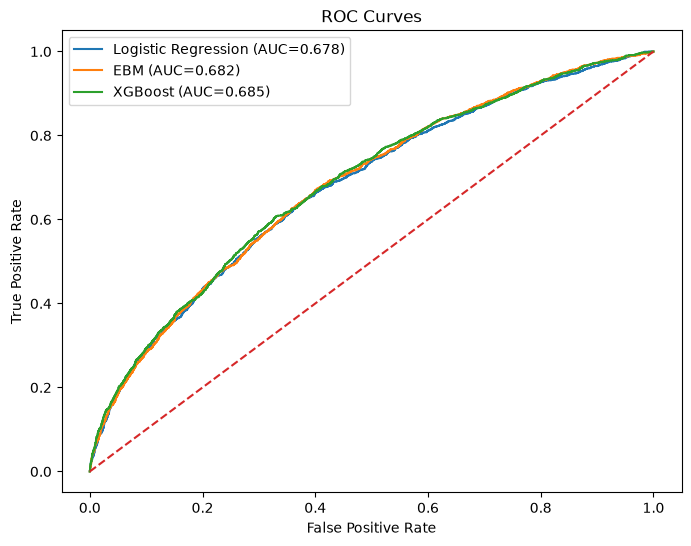

In [96]:
#comparing ROC curves
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_ebm, tpr_ebm, _ = roc_curve(y_test, y_prob_ebm)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb_cal)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC={roc_auc_score(y_test, y_prob_lr):.3f})"
)

plt.plot(
    fpr_ebm,
    tpr_ebm,
    label=f"EBM (AUC={roc_auc_score(y_test, y_prob_ebm):.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC={roc_auc_score(y_test, y_prob_xgb_cal):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()

plt.show()

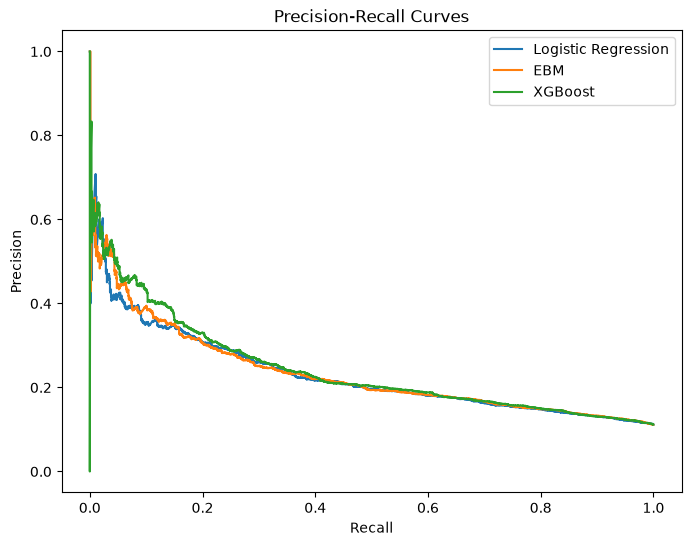

In [97]:
#compare Precision-Recall curves
from sklearn.metrics import precision_recall_curve

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test,
    y_prob_lr
)

precision_ebm, recall_ebm, _ = precision_recall_curve(
    y_test,
    y_prob_ebm
)

precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test,
    y_prob_xgb_cal
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_lr,
    precision_lr,
    label="Logistic Regression"
)

plt.plot(
    recall_ebm,
    precision_ebm,
    label="EBM"
)

plt.plot(
    recall_xgb,
    precision_xgb,
    label="XGBoost"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")

plt.legend()
plt.show()

In [98]:
#checking with different thresholds

thresholds = np.arange(
    0.05,
    0.96,
    0.05
)

threshold_results = []

for threshold in thresholds:
    
    metrics = calculate_metrics(
        y_test,
        y_prob_xgb_cal,
        threshold=threshold
    )
    
    threshold_results.append({
        "Threshold": threshold,
        **metrics
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Sensitivity,Specificity,PPV,NPV
0,0.05,0.972694,0.101980,0.120075,0.967368
1,0.10,0.723908,0.530235,0.162578,0.938439
2,0.15,0.424150,0.800856,0.211562,0.916937
3,0.20,0.256068,0.919731,0.286685,0.907521
4,0.25,0.143811,0.971638,0.389803,0.900078
5,0.30,0.082524,0.987692,0.457912,0.895233
6,0.35,0.043083,0.994878,0.514493,0.891920
7,0.40,0.017597,0.998548,0.604167,0.889721
8,0.45,0.003034,0.999847,0.714286,0.888398
9,0.50,0.000000,0.999924,0.000000,0.888104


In [99]:
# Compare thresholds using the validation threshold subset
thresholds = np.round(np.arange(0.05, 1.00, 0.05), 2)

threshold_results = []

for threshold in thresholds:
    metrics = calculate_metrics(
        y_threshold,
        y_prob_threshold_cal,
        threshold=threshold
    )

    threshold_results.append({
        "Threshold": threshold,
        **metrics
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,Sensitivity,Specificity,PPV,NPV
0,0.05,0.978102,0.097546,0.119554,0.972644
1,0.10,0.705596,0.533455,0.159297,0.935329
2,0.15,0.436740,0.796373,0.211799,0.918601
3,0.20,0.246959,0.914037,0.264668,0.906439
4,0.25,0.116788,0.968450,0.316832,0.897458
5,0.30,0.055961,0.985825,0.330935,0.892877
6,0.35,0.024331,0.994513,0.357143,0.890542
7,0.40,0.001217,0.998476,0.090909,0.888633
8,0.45,0.000000,1.000000,0.000000,0.888663
9,0.50,0.000000,1.000000,0.000000,0.888663


In [100]:
# Final test-set evaluation at the selected validation threshold
y_pred_xgb_test = (
    y_prob_xgb_cal >= global_threshold
).astype(int)

test_metrics = calculate_metrics(
    y_test,
    y_prob_xgb_cal,
    threshold=global_threshold
)

print("Selected threshold:", global_threshold)
print("Test-set metrics:", test_metrics)

Selected threshold: 0.10666526983717327
Test-set metrics: {'Sensitivity': np.float64(0.6850728155339806), 'Specificity': np.float64(0.5744973625869582), 'PPV': np.float64(0.16863330843913368), 'NPV': np.float64(0.9353995519044063)}


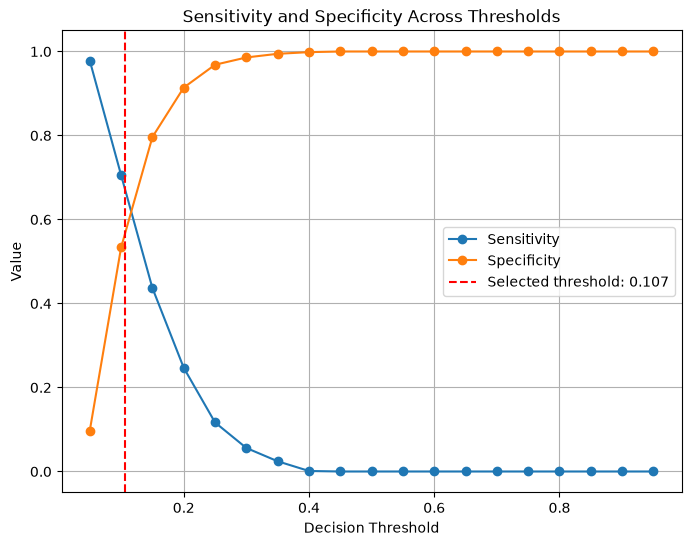

In [101]:
#plot sensitivity and specificity
plt.figure(figsize=(8, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Sensitivity"],
    marker="o",
    label="Sensitivity"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Specificity"],
    marker="o",
    label="Specificity"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Value")
plt.title("Sensitivity and Specificity Across Thresholds")
plt.legend()
plt.grid()

plt.axvline(
    global_threshold,
    color="red",
    linestyle="--",
    label=f"Selected threshold: {global_threshold:.3f}"
)
plt.legend()

plt.show()

In [102]:
#calibration curves for all models
from sklearn.calibration import calibration_curve

prob_true_lr, prob_pred_lr = calibration_curve(
    y_test,
    y_prob_lr,
    n_bins=10,
    strategy="quantile"
)

prob_true_ebm, prob_pred_ebm = calibration_curve(
    y_test,
    y_prob_ebm,
    n_bins=10,
    strategy="quantile"
)

prob_true_xgb, prob_pred_xgb = calibration_curve(
    y_test,
    y_prob_xgb_cal,
    n_bins=10,
    strategy="quantile"
)

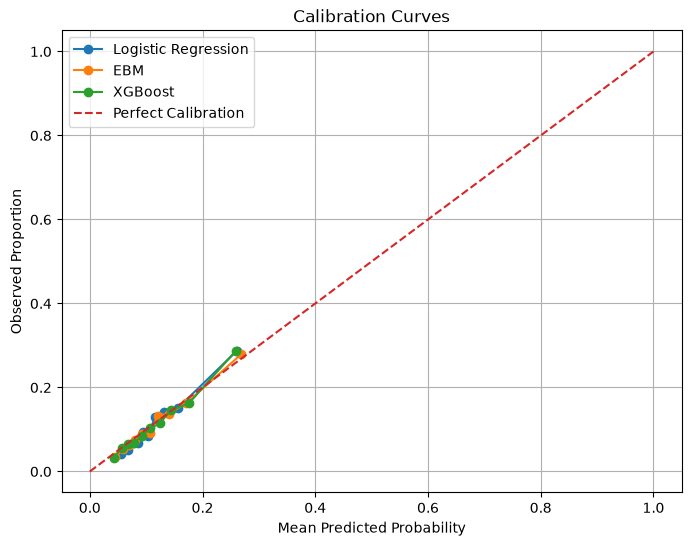

In [103]:
plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred_lr,
    prob_true_lr,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    prob_pred_ebm,
    prob_true_ebm,
    marker="o",
    label="EBM"
)

plt.plot(
    prob_pred_xgb,
    prob_true_xgb,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Proportion")
plt.title("Calibration Curves")
plt.legend()
plt.grid()

plt.show()

In [104]:
#calibration function

from scipy.special import logit
from sklearn.linear_model import LogisticRegression

def calibration_intercept_slope(y_true, y_prob):
    
    # Avoid probabilities of exactly 0 or 1
    p = np.clip(y_prob, 1e-6, 1 - 1e-6)
    
    log_odds = logit(p).reshape(-1, 1)
    
    model = LogisticRegression(
        penalty=None,
        solver="lbfgs"
    )
    
    model.fit(log_odds, y_true)
    
    intercept = model.intercept_[0]
    slope = model.coef_[0][0]
    
    return intercept, slope

In [105]:
cal_lr = calibration_intercept_slope(
    y_test,
    y_prob_lr
)

cal_ebm = calibration_intercept_slope(
    y_test,
    y_prob_ebm
)

cal_xgb = calibration_intercept_slope(
    y_test,
    y_prob_xgb_cal
)

print("Logistic Regression:", cal_lr)
print("EBM:", cal_ebm)
print("XGBoost:", cal_xgb)

Logistic Regression: (np.float64(0.24588885407603986), np.float64(1.142494174450079))
EBM: (np.float64(0.11958927681727274), np.float64(1.080931190961172))
XGBoost: (np.float64(0.26806326820483556), np.float64(1.1566885361561872))


C:\Users\umaya\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\umaya\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\umaya\anaconda3\Lib\site-packages\sklearn\linear_mo

In [106]:
calibration_results = pd.DataFrame({
    "Model": [
        "Penalised Logistic Regression",
        "EBM",
        "Calibrated XGBoost"
    ],
    
    "Brier Score": [
        brier_score_loss(y_test, y_prob_lr),
        brier_score_loss(y_test, y_prob_ebm),
        brier_score_loss(y_test, y_prob_xgb_cal)
    ],
    
    "Calibration Intercept": [
        cal_lr[0],
        cal_ebm[0],
        cal_xgb[0]
    ],
    
    "Calibration Slope": [
        cal_lr[1],
        cal_ebm[1],
        cal_xgb[1]
    ]
})

calibration_results

,Model,Brier Score,Calibration Intercept,Calibration Slope
0,Penalised Logistic Regression,0.094494,0.245889,1.142494
1,EBM,0.094130,0.119589,1.080931
2,Calibrated XGBoost,0.093830,0.268063,1.156689


Fairness analysis

In [107]:
print(X_test.columns.tolist())

['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [108]:
# Build a test-set dataframe for fairness analysis RQ2
fairness_df = X_test[["age", "gender", "race"]].copy().reset_index(drop=True)

fairness_df["actual"] = y_test.to_numpy()
fairness_df["probability"] = np.asarray(y_prob_xgb_cal)
fairness_df["prediction"] = (
    fairness_df["probability"] >= global_threshold
).astype(int)

print("Threshold used:", global_threshold)
fairness_df.head()

Threshold used: 0.10666526983717327


,age,gender,race,actual,probability,prediction
0,[40-50),Female,AfricanAmerican,0,0.128758,1
1,[60-70),Female,AfricanAmerican,0,0.062070,0
2,[80-90),Female,Caucasian,0,0.071607,0
3,[80-90),Female,Caucasian,0,0.114327,1
4,[70-80),Female,Caucasian,0,0.115506,1


In [109]:
fairness_df["race"].value_counts(dropna=False) #race group size

race
Caucasian          10947
AfricanAmerican     2867
NaN                  331
Hispanic             279
Other                205
Asian                100
Name: count, dtype: int64

In [110]:
fairness_df["gender"].value_counts(dropna=False) #gender group size

gender
Female    7880
Male      6849
Name: count, dtype: int64

In [111]:
fairness_df["age"].value_counts(dropna=False) #age group size

age
[70-80)     3731
[60-70)     3360
[50-60)     2535
[80-90)     2501
[40-50)     1427
[30-40)      538
[90-100)     356
[20-30)      281
Name: count, dtype: int64

In [112]:
#calculating True Positive Rate RQ2
def group_tpr(df, group_column):
    
    output = []
    
    for group, data in df.groupby(group_column, dropna=False):
        
        tn, fp, fn, tp = confusion_matrix(
            data["actual"],
            data["prediction"],
            labels=[0, 1]
        ).ravel()
        
        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        
        output.append({
            "Group": group,
            "N": len(data),
            "Positive Cases": data["actual"].sum(),
            "TPR": tpr
        })
    
    return pd.DataFrame(output)

In [113]:
race_tpr = group_tpr(
    fairness_df,
    "race"
)

race_tpr

,Group,N,Positive Cases,TPR
0,AfricanAmerican,2867,335,0.629851
1,Asian,100,9,0.666667
2,Caucasian,10947,1237,0.703314
3,Hispanic,279,26,0.653846
4,Other,205,14,0.642857
5,NaN,331,27,0.592593


In [114]:
gender_tpr = group_tpr(
    fairness_df,
    "gender"
)

gender_tpr

,Group,N,Positive Cases,TPR
0,Female,7880,878,0.712984
1,Male,6849,770,0.653247


In [115]:
age_tpr = group_tpr(
    fairness_df,
    "age"
)

age_tpr

,Group,N,Positive Cases,TPR
0,[20-30),281,39,0.871795
1,[30-40),538,68,0.632353
2,[40-50),1427,152,0.697368
3,[50-60),2535,229,0.602620
4,[60-70),3360,372,0.666667
5,[70-80),3731,437,0.702517
6,[80-90),2501,317,0.731861
7,[90-100),356,34,0.617647


In [116]:
#equal opportunity difference RQ2
def equal_opportunity_difference(tpr_table):
    
    valid_tpr = tpr_table["TPR"].dropna()
    
    return valid_tpr.max() - valid_tpr.min()

In [117]:
eo_race = equal_opportunity_difference(race_tpr)

print("Race Equal Opportunity Difference:", eo_race)

eo_gender = equal_opportunity_difference(gender_tpr)

print("Gender Equal Opportunity Difference:", eo_gender)

eo_age = equal_opportunity_difference(age_tpr)

print("Age Equal Opportunity Difference:", eo_age)

Race Equal Opportunity Difference: 0.110721877900536
Gender Equal Opportunity Difference: 0.05973730142295053
Age Equal Opportunity Difference: 0.2691747844586273


In [118]:
# Build one consistent test-set fairness dataframe
fairness_df = X_test[["age", "gender", "race"]].copy().reset_index(drop=True)

fairness_df["actual"] = np.asarray(y_test).astype(int)
fairness_df["probability"] = np.asarray(y_prob_xgb_cal)
fairness_df["prediction"] = (
    fairness_df["probability"] >= global_threshold
).astype(int)

assert len(fairness_df) == len(y_test) == len(y_prob_xgb_cal)

# Calculate classification metrics for each group RQ3
def subgroup_metrics(df, group_column):
    output = []

    for group, data in df.groupby(group_column, dropna=False):
        tn, fp, fn, tp = confusion_matrix(
            data["actual"],
            data["prediction"],
            labels=[0, 1]
        ).ravel()

        actual_positives = tp + fn
        actual_negatives = tn + fp
        
        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan #share of actual readmissions that model identified
        fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan #share of actual readmissions th model missed
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan #share of patients who were not readmitted but were incorrectly flagged
        specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan #share of patients who were not readmitted and were correctly identified
        
        output.append({
            "Group": group,
            "N": len(data), #total number of test records in each group
            "Positive Cases": data["actual"].sum(), #number of actual readmissions
            "TPR": tpr,
            "FNR": fnr,
            "FPR": fpr,
            "Specificity": specificity
        })
    
    return pd.DataFrame(output)

In [119]:
# Full race results
race_metrics = subgroup_metrics(fairness_df, "race")

race_tpr = race_metrics[
    ["Group", "N", "Positive Cases", "TPR"]
].copy()

print("Threshold used:", global_threshold)
display(race_tpr) #readmission detection by race
display(race_metrics)


Threshold used: 0.10666526983717327


,Group,N,Positive Cases,TPR
0,AfricanAmerican,2867,335,0.629851
1,Asian,100,9,0.666667
2,Caucasian,10947,1237,0.703314
3,Hispanic,279,26,0.653846
4,Other,205,14,0.642857
5,NaN,331,27,0.592593


,Group,N,Positive Cases,TPR,FNR,FPR,Specificity
0,AfricanAmerican,2867,335,0.629851,0.370149,0.432464,0.567536
1,Asian,100,9,0.666667,0.333333,0.307692,0.692308
2,Caucasian,10947,1237,0.703314,0.296686,0.433265,0.566735
3,Hispanic,279,26,0.653846,0.346154,0.332016,0.667984
4,Other,205,14,0.642857,0.357143,0.272251,0.727749
5,NaN,331,27,0.592593,0.407407,0.328947,0.671053


In [120]:
gender_metrics = subgroup_metrics(
    fairness_df,
    "gender"
)

gender_metrics


,Group,N,Positive Cases,TPR,FNR,FPR,Specificity
0,Female,7880,878,0.712984,0.287016,0.445301,0.554699
1,Male,6849,770,0.653247,0.346753,0.402698,0.597302


In [121]:
age_metrics = subgroup_metrics(
    fairness_df,
    "age"
)

age_metrics

,Group,N,Positive Cases,TPR,FNR,FPR,Specificity
0,[20-30),281,39,0.871795,0.128205,0.347107,0.652893
1,[30-40),538,68,0.632353,0.367647,0.327660,0.672340
2,[40-50),1427,152,0.697368,0.302632,0.319216,0.680784
3,[50-60),2535,229,0.602620,0.397380,0.311795,0.688205
4,[60-70),3360,372,0.666667,0.333333,0.392570,0.607430
5,[70-80),3731,437,0.702517,0.297483,0.484214,0.515786
6,[80-90),2501,317,0.731861,0.268139,0.565476,0.434524
7,[90-100),356,34,0.617647,0.382353,0.618012,0.381988


Bootstrap confidence intervals

In [122]:
if "patient_nbr" not in fairness_df.columns:
    fairness_df["patient_nbr"] = np.asarray(groups_test)

In [123]:
#RQ2
def bootstrap_tpr_ci_by_patient(
    data,
    patient_column="patient_nbr",
    n_bootstrap=1000,
    random_state=42
):
    data = data.dropna(subset=[patient_column]).copy()
    patient_ids = data[patient_column].unique()

    if len(patient_ids) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(random_state)
    rows_by_patient = {
        patient_id: data[data[patient_column] == patient_id]
        for patient_id in patient_ids
    }

    bootstrap_tprs = []

    for _ in range(n_bootstrap):
        sampled_ids = rng.choice(
            patient_ids,
            size=len(patient_ids),
            replace=True
        )

        # Keep all encounters from each sampled patient together
        sample = pd.concat(
            [rows_by_patient[patient_id] for patient_id in sampled_ids],
            ignore_index=True
        )

        actual_readmissions = sample["actual"] == 1

        if actual_readmissions.any():
            tpr = sample.loc[
                actual_readmissions, "prediction"
            ].mean()
            bootstrap_tprs.append(tpr)

    if not bootstrap_tprs:
        return np.nan, np.nan

    return (
        np.percentile(bootstrap_tprs, 2.5),
        np.percentile(bootstrap_tprs, 97.5)
    )

In [ ]:
race_ci_results = []

for group, data in fairness_df.groupby("race", dropna=False):
    lower, upper = bootstrap_tpr_ci_by_patient(data)

    actual_readmissions = data["actual"] == 1

    race_ci_results.append({
        "Race": group,
        "N encounters": len(data),
        "Positive cases": int(data["actual"].sum()),
        "TPR": data.loc[actual_readmissions, "prediction"].mean(),
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })

race_ci_df = pd.DataFrame(race_ci_results)
display(race_ci_df)

In [ ]:
age_ci_results = []

for group, data in fairness_df.groupby("age", dropna=False):
    lower, upper = bootstrap_tpr_ci_by_patient(data)

    actual_readmissions = data["actual"] == 1

    age_ci_results.append({
        "Age group": group,
        "N encounters": len(data),
        "Positive cases": int(data["actual"].sum()),
        "TPR": data.loc[actual_readmissions, "prediction"].mean(),
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })

age_ci_df = pd.DataFrame(age_ci_results)
display(age_ci_df)

In [ ]:
gender_ci_results = []

for group, data in fairness_df.groupby("gender", dropna=False):
    lower, upper = bootstrap_tpr_ci_by_patient(data)

    actual_readmissions = data["actual"] == 1

    gender_ci_results.append({
        "Gender": group,
        "N encounters": len(data),
        "Positive cases": int(data["actual"].sum()),
        "Unique patients": data["patient_nbr"].nunique(),
        "TPR": data.loc[actual_readmissions, "prediction"].mean(),
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })

gender_ci_df = pd.DataFrame(gender_ci_results)
display(gender_ci_df)

SHAP Explainability

In [ ]:
#XGBoost classifier
xgb_preprocessor_fitted = xgb_model.named_steps["preprocessor"] #preprocessor that handled missing values and encoded categorical variables
xgb_classifier = xgb_model.named_steps["classifier"] #trained xgboost model that made predictions
print(xgb_classifier)

In [ ]:
X_test_xgb_transformed = xgb_preprocessor_fitted.transform(X_test)

print("Transformed test shape:", X_test_xgb_transformed.shape)

In [ ]:
feature_names_xgb = xgb_preprocessor_fitted.get_feature_names_out()

print("Number of transformed features:", len(feature_names_xgb))

In [ ]:
print(feature_names_xgb[:20])

In [ ]:
#creating the SHAP explainer for trained model
import shap

explainer = shap.TreeExplainer(
    xgb_classifier
)

In [ ]:
#SHAP value calculating for all the patients
shap_values = explainer.shap_values(
    X_test_xgb_transformed
)

In [ ]:
print("SHAP values shape:", shap_values.shape)
print("Test data shape:", X_test_xgb_transformed.shape)

In [ ]:
#feature importance summary plot
shap.summary_plot(
    shap_values,
    X_test_xgb_transformed,
    feature_names=feature_names_xgb,
    plot_type="bar"
)

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_xgb_transformed,
    feature_names=feature_names_xgb
)

In [ ]:
#SHAP importance table
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names_xgb,
    "Mean Absolute SHAP": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

shap_importance.head(20)

In [ ]:
shap_importance.to_csv(
    "xgboost_shap_feature_importance.csv",
    index=False
)

In [ ]:
#Individual patient explanation
patient_index = 0 #1st patient in the dataset
print("Actual outcome:", y_test.iloc[patient_index])
print("Predicted probability:", y_prob_xgb[patient_index])

In [ ]:
patient_shap = shap_values[patient_index]

In [ ]:
#SHAP waterfall plot
patient_data = X_test_xgb_transformed[patient_index].toarray().flatten()
shap.waterfall_plot(
    shap.Explanation(
        values=patient_shap,
        base_values=explainer.expected_value,
        data=patient_data,
        feature_names=feature_names_xgb
    ),
    max_display=15
)

In [ ]:
shap_test = X_test[
    ["age", "gender", "race"]
].copy()

shap_test["row_position"] = np.arange(
    len(shap_test)
)

In [ ]:
#table that conbines the SHAP values with each patient's demographic info
shap_df = pd.DataFrame(
    shap_values,
    columns=feature_names_xgb
)

shap_df["row_position"] = np.arange(
    len(shap_df)
)

shap_df = shap_test.merge(
    shap_df,
    on="row_position"
)

In [ ]:
shap_df.head()

In [ ]:
#SHAP importance by race
race_shap = {}

for race_group, data in shap_df.groupby(
    "race",
    dropna=False
):
    
    feature_values = data[
        feature_names_xgb
    ]
    
    race_shap[race_group] = (
        np.abs(feature_values).mean()
    )

In [ ]:
race_shap_df = pd.DataFrame(
    race_shap
).T

In [ ]:
race_shap_df.head()

In [ ]:
for race_group in race_shap_df.index:
    
    print("\nRace:", race_group)
    
    print(
        race_shap_df.loc[race_group]
        .sort_values(ascending=False)
        .head(10)
    )

In [ ]:
#SHAP importance by gender
gender_shap = {}

for gender_group, data in shap_df.groupby(
    "gender",
    dropna=False
):
    
    feature_values = data[
        feature_names_xgb
    ]
    
    gender_shap[gender_group] = (
        np.abs(feature_values).mean()
    )

gender_shap_df = pd.DataFrame(
    gender_shap
).T

In [ ]:
gender_shap_df

In [ ]:
for gender_group in gender_shap_df.index:
    
    print("\nGender:", gender_group)
    
    print(
        gender_shap_df.loc[gender_group]
        .sort_values(ascending=False)
        .head(10)
    )

In [ ]:
#SHAP importance by age
age_shap = {}

for age_group, data in shap_df.groupby(
    "age",
    dropna=False
):
    
    feature_values = data[
        feature_names_xgb
    ]
    
    age_shap[age_group] = (
        np.abs(feature_values).mean()
    )

age_shap_df = pd.DataFrame(
    age_shap
).T

In [ ]:
for age_group in age_shap_df.index:
    
    print("\nAge:", age_group)
    
    print(
        age_shap_df.loc[age_group]
        .sort_values(ascending=False)
        .head(10)
    )

In [ ]:
#stability function
def get_shap_ranking(
    model,
    X_data,
    sample_size=2000,
    random_state=42
):
    
    rng = np.random.default_rng(random_state)
    
    sample_size = min(
        sample_size,
        len(X_data)
    )
    
    sample_indices = rng.choice(
        len(X_data),
        size=sample_size,
        replace=False
    )
    
    X_sample = X_data.iloc[
        sample_indices
    ]
    
    preprocessor = model.named_steps[
        "preprocessor"
    ]
    
    classifier = model.named_steps[
        "classifier"
    ]
    
    X_transformed = preprocessor.transform(
        X_sample
    )
    
    feature_names = (
        preprocessor.get_feature_names_out()
    )
    
    explainer = shap.TreeExplainer(
        classifier
    )
    
    values = explainer.shap_values(
        X_transformed
    )
    
    importance = np.abs(values).mean(
        axis=0
    )
    
    ranking = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values(
        "Importance",
        ascending=False
    )
    
    return ranking

In [ ]:
ranking_1 = get_shap_ranking(
    xgb_model,
    X_test,
    sample_size=2000,
    random_state=42
)
ranking_1.head(20)

In [ ]:
ranking_2 = get_shap_ranking(
    xgb_model,
    X_test,
    sample_size=2000,
    random_state=123
)
ranking_2.head(20)

In [ ]:
ranking_3 = get_shap_ranking(
    xgb_model,
    X_test,
    sample_size=2000,
    random_state=456
)
ranking_3.head(20)

In [ ]:
#comparing features

In [ ]:
shap_importance.to_csv(
    "xgboost_shap_importance.csv",
    index=False
)

In [ ]:
race_shap_df.to_csv(
    "shap_importance_by_race.csv"
)

gender_shap_df.to_csv(
    "shap_importance_by_gender.csv"
)

age_shap_df.to_csv(
    "shap_importance_by_age.csv"
)

In [ ]:
from scipy.stats import spearmanr
from itertools import combinations

rankings = {
    "Sample 1": ranking_1,
    "Sample 2": ranking_2,
    "Sample 3": ranking_3
}

stability_rows = []

for left, right in combinations(rankings, 2):
    a = rankings[left].set_index("Feature")["Importance"]
    b = rankings[right].set_index("Feature")["Importance"]

    aligned = pd.concat([a, b], axis=1).fillna(0)

    top_a = set(a.nlargest(10).index)
    top_b = set(b.nlargest(10).index)

    stability_rows.append({
        "Comparison": f"{left} versus {right}",
        "Spearman correlation": spearmanr(
            aligned.iloc[:, 0],
            aligned.iloc[:, 1]
        ).statistic,
        "Top-10 Jaccard": (
            len(top_a & top_b) / len(top_a | top_b)
        )
    })

pd.DataFrame(stability_rows)

LACE implementation

In [ ]:
# Columns relevant to LACE implementation

lace_columns = [
    "time_in_hospital",
    "admission_type_id",
    "diag_1",
    "diag_2",
    "diag_3",
    "number_emergency"
]

for col in lace_columns:
    print(col, ":", col in df.columns)

In [ ]:
def calculate_L(days):
    if days == 1:
        return 1
    elif days == 2:
        return 2
    elif days == 3:
        return 3
    elif days <= 6:
        return 4
    elif days <= 13:
        return 5
    else:
        return 7


df["lace_L"] = df["time_in_hospital"].apply(calculate_L)

df[[
    "time_in_hospital",
    "lace_L"
]].head(10)

In [ ]:
df["lace_L"].value_counts().sort_index()

In [ ]:
df["admission_type_id"].value_counts().sort_index()

In [ ]:
def calculate_A(admission_type):

    if admission_type in [1, 2, 7]:
        return 3 # emergency, urgent and trauma
    
    elif admission_type == 3:
        return 0 # elective
    
    else:
        return 0 #newborn, unavailable, null and not mapped


df["lace_A"] = df["admission_type_id"].apply(calculate_A)

df[
    ["admission_type_id", "lace_A"]
].value_counts().sort_index()

In [ ]:
df["lace_E"] = df["number_emergency"]

In [ ]:
def calculate_E(ed_visits):

    if ed_visits == 0:
        return 0
    elif ed_visits == 1:
        return 1
    elif ed_visits == 2:
        return 2
    elif ed_visits == 3:
        return 3
    else:
        return 4


df["lace_E"] = df["number_emergency"].apply(calculate_E)

In [ ]:
df[
    ["number_emergency", "lace_E"]
].head(20)

In [ ]:
diagnosis_cols = ["diag_1", "diag_2", "diag_3"]

df[diagnosis_cols].head(20)

In [ ]:
# Check how many non-missing diagnosis values exist

for col in diagnosis_cols:
    print(
        col,
        "non-missing:",
        df[col].notna().sum(),
        "missing:",
        df[col].isna().sum()
    )

In [ ]:
for col in diagnosis_cols:
    print("\n", col)
    print(df[col].dropna().head(20).tolist())

In [ ]:
# Deyo-Charlson ICD-9 diagnosis classification
# ------------------------------------------------

def classify_charlson(code):

    if pd.isna(code):
        return None #cheking for missing values

    code = str(code).strip()

    code_clean = code.replace(".", "")  #remove decimal point

    #convert to numeric
    try:
        num = float(code)
    except:
        num = None

    # 1. Myocardial infarction
    # -------------------------------------------------
    if num is not None:
        if 410 <= num < 411 or num == 412:
            return "myocardial_infarction"

    # 2. Congestive heart failure
    # -----------------------------------------------------
    if num is not None:
        if 428 <= num < 429:
            return "congestive_heart_failure"

    # 3. Peripheral vascular disease
    # ----------------------------------------------------
    if num is not None:
        if (
            441 <= num < 442
            or num == 443.9
            or num == 785.4
        ):
            return "peripheral_vascular_disease"

    # 4. Cerebrovascular disease
    # ----------------------------------------------------
    if num is not None:
        if 430 <= num < 439:
            return "cerebrovascular_disease"

    # 5. Dementia
    # -----------------------------------------------------
    if num is not None:
        if 290 <= num < 291:
            return "dementia"

    # 6. Chronic pulmonary disease
    # -----------------------------------------------------
    if num is not None:
        if 490 <= num < 497 or 500 <= num < 506:
            return "chronic_pulmonary_disease"

    # 7. Connective tissue / rheumatologic disease
    # ---------------------------------------------------
    if num is not None:
        if (
            710 <= num < 711
            or 714 <= num < 715
            or num == 725
        ):
            return "rheumatologic_disease"

    # 8. Peptic ulcer disease
    # ----------------------------------------------------
    if num is not None:
        if 531 <= num < 535:
            return "peptic_ulcer_disease"

    # 9. Mild liver disease
    # ---------------------------------------------------
    if num is not None:
        if (
            571.2 <= num <= 571.6
        ):
            return "mild_liver_disease"

    # 10. Diabetes without complications
    # --------------------------------------------------
    if num is not None:
        if (
            250.0 <= num <= 250.39
            or 250.7 <= num <= 250.79
        ):
            return "diabetes"

    # 11. Hemiplegia / paraplegia
    # ---------------------------------------------------
    if num is not None:
        if (
            342 <= num < 343
            or 344.1 <= num < 344.2
        ):
            return "hemiplegia"

    # 12. Renal disease
    # ------------------------------------------------
    if num is not None:
        if (
            582 <= num < 583
            or 583.0 <= num < 584
            or 585 <= num < 586
            or 586 <= num < 587
            or 588 <= num < 589
        ):
            return "renal_disease"

    # 13. Diabetes with chronic complications
    # ---------------------------------------------------
    if num is not None:
        if 250.4 <= num <= 250.69:
            return "diabetes_complicated"

    # 14. Any malignancy
    # ----------------------------------------------------
    if num is not None:
        if (
            140 <= num < 173
            or 174 <= num < 196
            or 200 <= num < 209
        ):
            return "malignancy"

    # 15. Moderate/severe liver disease
    # -----------------------------------------------------
    if num is not None:
        if (
            572.2 <= num <= 572.8
            or 456.0 <= num <= 456.2
        ):
            return "severe_liver_disease"

    # 16. Metastatic solid tumour
    # ---------------------------------------------------
    if num is not None:
        if 196 <= num < 200:
            return "metastatic_tumor"

    # 17. AIDS/HIV
    # ---------------------------------------------------
    if num is not None:
        if 42 <= num < 45:
            return "aids"

    return None

In [ ]:
test_codes = [
    "410",
    "428",
    "250.00",
    "250.50",
    "585",
    "572.3",
    "196",
    "042"
]

for code in test_codes:
    print(code, "->", classify_charlson(code))

In [ ]:
for col in ["diag_1", "diag_2", "diag_3"]:
    df[col + "_charlson"] = df[col].apply(classify_charlson)

In [ ]:
df[
    [
        "diag_1",
        "diag_1_charlson",
        "diag_2",
        "diag_2_charlson",
        "diag_3",
        "diag_3_charlson"
    ]
].head(20)

In [ ]:
charlson_weights = {
    "myocardial_infarction": 1,
    "congestive_heart_failure": 1,
    "peripheral_vascular_disease": 1,
    "cerebrovascular_disease": 1,
    "dementia": 1,
    "chronic_pulmonary_disease": 1,
    "rheumatologic_disease": 1,
    "peptic_ulcer_disease": 1,
    "mild_liver_disease": 1,
    "diabetes": 1,

    "hemiplegia": 2,
    "renal_disease": 2,
    "diabetes_complicated": 2,
    "malignancy": 2,

    "severe_liver_disease": 3,

    "metastatic_tumor": 6,
    "aids": 6
}

In [ ]:
def calculate_adapted_cci(row):

    categories = set()

    # Get Charlson categories from all three diagnosis fields
    for col in [
        "diag_1_charlson",
        "diag_2_charlson",
        "diag_3_charlson"
    ]:
        if pd.notna(row[col]):
            categories.add(row[col])

    score = 0

    # 1-point conditions
    # --------------------------------------------------

    one_point_conditions = [
        "myocardial_infarction",
        "congestive_heart_failure",
        "peripheral_vascular_disease",
        "cerebrovascular_disease",
        "dementia",
        "chronic_pulmonary_disease",
        "rheumatologic_disease",
        "peptic_ulcer_disease"
    ]

    for condition in one_point_conditions:
        if condition in categories:
            score += 1

    # Diabetes
    # Complicated diabetes replaces uncomplicated diabetes
    # --------------------------------------------------

    if "diabetes_complicated" in categories:
        score += 2

    elif "diabetes" in categories:
        score += 1

    # Renal disease
    # --------------------------------------------------

    if "renal_disease" in categories:
        score += 2

    # Hemiplegia
    # ------------------------------------------------

    if "hemiplegia" in categories:
        score += 2

    # Liver disease
    # Severe replaces mild
    # --------------------------------------------------

    if "severe_liver_disease" in categories:
        score += 3

    elif "mild_liver_disease" in categories:
        score += 1

    # Cancer
    # Metastatic tumour replaces ordinary malignancy
    # ------------------------------------------------

    if "metastatic_tumor" in categories:
        score += 6

    elif "malignancy" in categories:
        score += 2

    # AIDS
    # --------------------------------------------------------

    if "aids" in categories:
        score += 6

    return score

In [ ]:
df["charlson_score"] = df.apply(
    calculate_adapted_cci,
    axis=1
)

In [ ]:
def convert_to_lace_C(charlson_score):
    if charlson_score >= 4:
        return 5
    else:
        return charlson_score

df["lace_C"] = df["charlson_score"].apply(convert_to_lace_C)

In [ ]:
df[
    [
        "diag_1",
        "diag_2",
        "diag_3",
        "lace_C"
    ]
].head(20)

In [ ]:
df["lace_C"].describe()

In [ ]:
df["lace_C"].value_counts().sort_index()

In [ ]:
for col in [
    "diag_1_charlson",
    "diag_2_charlson",
    "diag_3_charlson"
]:
    print("\n", col)
    print(df[col].value_counts())

In [ ]:
import matplotlib.pyplot as plt

df["lace_C"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Adapted Charlson Comorbidity Score")
plt.ylabel("Number of encounters")
plt.title("Distribution of Adapted Charlson Comorbidity Scores")
plt.show()

In [ ]:
df["LACE_score"] = (
    df["lace_L"]
    + df["lace_A"]
    + df["lace_C"]
    + df["lace_E"]
)

In [ ]:
df[
    [
        "lace_L",
        "lace_A",
        "lace_C",
        "lace_E",
        "LACE_score"
    ]
].head(20)

In [ ]:
df["LACE_score"].describe()

In [ ]:
# Align the adapted LACE score to the exact held-out test encounter indices.
assert df.index.equals(pd.RangeIndex(len(df)))
assert X_test.index.equals(y_test.index)
assert X_test.index.isin(df.index).all()

y_test_lace = y_test.copy()
lace_test = df.loc[X_test.index, "LACE_score"].astype(float).copy()
assert len(lace_test) == len(y_test_lace)
assert lace_test.index.equals(y_test_lace.index)
print("LACE test rows aligned:", len(lace_test))


In [ ]:
from sklearn.metrics import roc_auc_score

lace_auc = roc_auc_score(
    y_test_lace,
    lace_test
)

print("LACE ROC-AUC:", lace_auc)

In [ ]:
from sklearn.metrics import average_precision_score

lace_pr_auc = average_precision_score(
    y_test_lace,
    lace_test
)

print("LACE PR-AUC:", lace_pr_auc)

In [ ]:
# Compare models using calibrated XGBoost probabilities.
# The adapted LACE integer score is not a probability, so its Brier score is not defined here.
results = pd.DataFrame({
    "Model": [
        "Penalised Logistic Regression",
        "Explainable Boosting Machine",
        "Calibrated XGBoost",
        "Adapted LACE (exploratory)"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_ebm),
        roc_auc_score(y_test, y_prob_xgb_cal),
        roc_auc_score(y_test_lace, lace_test)
    ],
    "PR-AUC": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_ebm),
        average_precision_score(y_test, y_prob_xgb_cal),
        average_precision_score(y_test_lace, lace_test)
    ],
    "Brier Score": [
        brier_score_loss(y_test, y_prob_lr),
        brier_score_loss(y_test, y_prob_ebm),
        brier_score_loss(y_test, y_prob_xgb_cal),
        np.nan
    ]
})

display(results)


Fairness mitigation

In [ ]:
#calculating training sample weights
import numpy as np
import pandas as pd

def calculate_reweighing_weights(X, y, attribute):

    data = pd.DataFrame({
        "group": X[attribute].fillna("Unknown").to_numpy(),
        "target": np.asarray(y)
    })

    n = len(data)

    group_counts = data["group"].value_counts()
    target_counts = data["target"].value_counts()

    joint_counts = data.groupby(
        ["group", "target"]
    ).size()

    weights = []

    for group, target in zip(
        data["group"],
        data["target"]
    ):

        joint_count = joint_counts.loc[(group, target)]

        weight = (
            group_counts[group] * target_counts[target]
        ) / (n * joint_count)

        weights.append(weight)

    return np.asarray(weights)


race_weights = calculate_reweighing_weights(
    X_train,
    y_train,
    "race"
)

print("Minimum weight:", race_weights.min())
print("Maximum weight:", race_weights.max())
print("Average weight:", race_weights.mean())

In [ ]:
#retraining xgboost using the weights
from sklearn.base import clone

xgb_reweighted = clone(xgb_model)

xgb_reweighted.fit(
    X_train,
    y_train,
    classifier__sample_weight=race_weights
)

print("Reweighted XGBoost training completed.")

In [ ]:
#predict using the reweighted model
y_prob_reweighted = xgb_reweighted.predict_proba(
    X_test
)[:, 1]

y_pred_reweighted = (
    y_prob_reweighted >= 0.5
).astype(int)

In [ ]:
import shap

original_preprocessor = xgb_model.named_steps["preprocessor"]
original_classifier = xgb_model.named_steps["classifier"]

weighted_preprocessor = xgb_reweighted.named_steps["preprocessor"]
weighted_classifier = xgb_reweighted.named_steps["classifier"]

# Same test patients
X_sample = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

X_original = original_preprocessor.transform(X_sample)
X_weighted = weighted_preprocessor.transform(X_sample)

explainer_original = shap.TreeExplainer(
    original_classifier
)

explainer_weighted = shap.TreeExplainer(
    weighted_classifier
)

shap_original = explainer_original.shap_values(X_original)
shap_weighted = explainer_weighted.shap_values(X_weighted)

In [ ]:
features_original = original_preprocessor.get_feature_names_out()
features_weighted = weighted_preprocessor.get_feature_names_out()

original_importance = pd.DataFrame({
    "Feature": features_original,
    "Original SHAP": np.abs(shap_original).mean(axis=0)
})

weighted_importance = pd.DataFrame({
    "Feature": features_weighted,
    "Reweighted SHAP": np.abs(shap_weighted).mean(axis=0)
})

shap_comparison = original_importance.merge(
    weighted_importance,
    on="Feature"
)

shap_comparison["Change"] = (
    shap_comparison["Reweighted SHAP"]
    - shap_comparison["Original SHAP"]
)

display(
    shap_comparison.sort_values(
        "Original SHAP",
        ascending=False
    ).head(15)
)

Comparing approaches

In [ ]:
# RQ3: Compare global, race, gender, age-specific thresholds,
# and reweighted XGBoost.

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator


#calibrate the reweighted model using the heldout calibration patients.
calibrated_reweighted_xgb = CalibratedClassifierCV(
    estimator=FrozenEstimator(xgb_reweighted),
    method="sigmoid"
)
calibrated_reweighted_xgb.fit(X_cal, y_cal)


#probabilities for validation threshold selection and final test evaluation.
p_base_threshold = calibrated_xgb.predict_proba(X_threshold)[:, 1]
p_base_test = calibrated_xgb.predict_proba(X_test)[:, 1]

p_reweighted_threshold = (
    calibrated_reweighted_xgb.predict_proba(X_threshold)[:, 1]
)
p_reweighted_test = (
    calibrated_reweighted_xgb.predict_proba(X_test)[:, 1]
)


def clean_group_labels(values):
    """Convert group labels to strings and label missing values Unknown."""
    labels = pd.Series(values).astype("object")
    return labels.where(labels.notna(), "Unknown").astype(str).to_numpy()


def youden_threshold(y_true, probability):
    """Select the threshold maximizing sensitivity minus false positive rate."""
    fpr, tpr, thresholds = roc_curve(y_true, probability)
    valid = np.isfinite(thresholds)

    if not valid.any():
        return 0.5

    best_position = np.flatnonzero(valid)[
        np.argmax((tpr - fpr)[valid])
    ]
    return float(thresholds[best_position])


# Select global thresholds using validation data only.
base_global_threshold = youden_threshold(
    y_threshold,
    p_base_threshold
)
reweighted_global_threshold = youden_threshold(
    y_threshold,
    p_reweighted_threshold
)


base_validation_predictions = (
    p_base_threshold >= base_global_threshold
).astype(int)

positive_validation = np.asarray(y_threshold) == 1

target_validation_tpr = (
    base_validation_predictions[positive_validation].mean()
    if positive_validation.any()
    else 0.5
)


def select_group_thresholds(
    y_true,
    probability,
    group_values,
    target_tpr,
    minimum_positives=20
):
    """
    Select a separate threshold for each sufficiently supported group.
    Groups without enough positive cases use the global threshold.
    """
    y_true = np.asarray(y_true).astype(int)
    probability = np.asarray(probability)
    group_values = clean_group_labels(group_values)

    thresholds_by_group = {}
    positive_counts = {}

    for group in np.unique(group_values):
        mask = group_values == group
        group_y = y_true[mask]
        group_probability = probability[mask]

        n_positive = int((group_y == 1).sum())
        positive_counts[group] = n_positive

        if n_positive < minimum_positives:
            continue
        if len(np.unique(group_y)) < 2:
            continue

        fpr, tpr, thresholds = roc_curve(
            group_y,
            group_probability
        )
        valid_positions = np.flatnonzero(np.isfinite(thresholds))

        if len(valid_positions) == 0:
            continue

        selected_position = min(
            valid_positions,
            key=lambda j: (
                abs(tpr[j] - target_tpr),
                fpr[j]
            )
        )

        thresholds_by_group[group] = float(
            thresholds[selected_position]
        )

    return thresholds_by_group, positive_counts


#selecting thresholds separately for race, gender and age.
sensitive_attributes = ["race", "gender", "age"]
thresholds_by_attribute = {}
validation_counts_by_attribute = {}
predictions_by_attribute = {}

for attribute in sensitive_attributes:
    thresholds, positive_counts = select_group_thresholds(
        y_true=y_threshold,
        probability=p_base_threshold,
        group_values=X_threshold[attribute],
        target_tpr=target_validation_tpr,
        minimum_positives=20
    )

    thresholds_by_attribute[attribute] = thresholds
    validation_counts_by_attribute[attribute] = positive_counts

    test_groups = clean_group_labels(X_test[attribute])

    predictions_by_attribute[attribute] = np.array([
        probability >= thresholds.get(group, base_global_threshold)
        for probability, group in zip(p_base_test, test_groups)
    ], dtype=int)

    fallback_groups = {
        group: count
        for group, count in positive_counts.items()
        if group not in thresholds
    }

    print(f"\n{attribute.title()} thresholds:", thresholds)
    print(
        f"{attribute.title()} groups using global threshold:",
        fallback_groups
    )


#predictions from the global-threshold baseline and reweighted model.
pred_baseline = (
    p_base_test >= base_global_threshold
).astype(int)

pred_reweighted = (
    p_reweighted_test >= reweighted_global_threshold
).astype(int)

print("\nBaseline global threshold:", base_global_threshold)
print("Reweighted global threshold:", reweighted_global_threshold)
print("Validation target TPR:", target_validation_tpr)


def classification_summary(y_true, probability, prediction):
    """Overall test-set classification and probability metrics."""
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction,
        labels=[0, 1]
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y_true, probability),
        "PR-AUC": average_precision_score(y_true, probability),
        "Brier": brier_score_loss(y_true, probability),
        "Accuracy": accuracy_score(y_true, prediction),
        "Sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "PPV": tp / (tp + fp) if (tp + fp) else np.nan,
        "FNR": fn / (fn + tp) if (fn + tp) else np.nan
    }


def subgroup_metrics(
    y_true,
    predictions,
    sensitive_values,
    minimum_positives=20
):
    """Calculate group TPR, FNR and specificity on the test set."""
    data = pd.DataFrame({
        "actual": np.asarray(y_true).astype(int),
        "prediction": np.asarray(predictions).astype(int),
        "group": clean_group_labels(sensitive_values)
    })

    rows = []

    for group, part in data.groupby("group", dropna=False):
        tn, fp, fn, tp = confusion_matrix(
            part["actual"],
            part["prediction"],
            labels=[0, 1]
        ).ravel()

        positives = tp + fn
        negatives = tn + fp

        rows.append({
            "Group": group,
            "N": len(part),
            "Positive cases": positives,
            "TPR": tp / positives if positives else np.nan,
            "FNR": fn / positives if positives else np.nan,
            "Specificity": tn / negatives if negatives else np.nan,
            "Included in EOD": positives >= minimum_positives
        })

    return pd.DataFrame(rows)


def supported_eod(
    y_true,
    predictions,
    sensitive_values,
    minimum_positives=20
):
    """Calculate EOD using groups with enough positive test cases."""
    metrics = subgroup_metrics(
        y_true,
        predictions,
        sensitive_values,
        minimum_positives=minimum_positives
    )

    supported_tprs = metrics.loc[
        metrics["Included in EOD"] & metrics["TPR"].notna(),
        "TPR"
    ]

    if len(supported_tprs) < 2:
        return np.nan

    return float(supported_tprs.max() - supported_tprs.min())


# Each strategy uses the same held-out test set.
strategies = {
    "Calibrated XGBoost (global threshold)": (
        p_base_test,
        pred_baseline
    ),
    "Calibrated XGBoost (race thresholds)": (
        p_base_test,
        predictions_by_attribute["race"]
    ),
    "Calibrated XGBoost (gender thresholds)": (
        p_base_test,
        predictions_by_attribute["gender"]
    ),
    "Calibrated XGBoost (age thresholds)": (
        p_base_test,
        predictions_by_attribute["age"]
    ),
    "Calibrated reweighted XGBoost": (
        p_reweighted_test,
        pred_reweighted
    )
}

sensitive_test = {
    "race": X_test["race"],
    "gender": X_test["gender"],
    "age": X_test["age"]
}


# Overall metrics and EOD for each strategy.
rq3_rows = []

for strategy_name, (probability, prediction) in strategies.items():
    row = {"Strategy": strategy_name}
    row.update(
        classification_summary(y_test, probability, prediction)
    )

    for attribute, values in sensitive_test.items():
        row[f"{attribute} EOD"] = supported_eod(
            y_test,
            prediction,
            values,
            minimum_positives=20
        )

    rq3_rows.append(row)

rq3_tradeoff_results = pd.DataFrame(rq3_rows)
display(rq3_tradeoff_results.round(4))


# Group-level TPR, FNR and specificity for each strategy.
rq3_subgroup_results = []

for strategy_name, (_, prediction) in strategies.items():
    for attribute, values in sensitive_test.items():
        table = subgroup_metrics(
            y_test,
            prediction,
            values,
            minimum_positives=20
        )
        table.insert(0, "Attribute", attribute)
        table.insert(0, "Strategy", strategy_name)
        rq3_subgroup_results.append(table)

rq3_subgroup_results = pd.concat(
    rq3_subgroup_results,
    ignore_index=True
)

display(rq3_subgroup_results.round(4))